<a href="https://colab.research.google.com/github/muhammad-usman-tech/data-analysis-tasks/blob/main/claud_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

total duplicates : 0
--- Data Coverage Grid (Number of orders per month) ---
month_id  1   2    3   4    5   6   7    8   9    10   11   12
year_id                                                       
2003      39  41   50  58   58  46  50   58  76  158  296   70
2004      91  86   56  64   74  85  91  133  95  159  301  110
2005      99  97  106  56  120   0   0    0   0    0    0    0


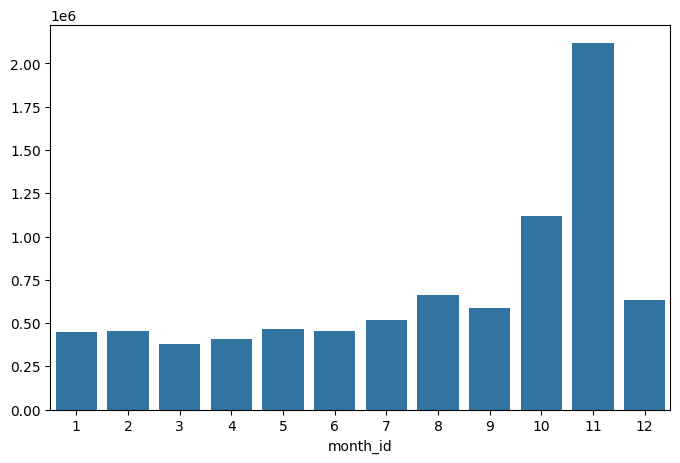

Top 10 Customers Revenue Breakdown:


,sales
customername,
Euro Shopping Channel,912294.11
Mini Gifts Distributors Ltd.,654858.06
"Australian Collectors, Co.",200995.41
Muscle Machine Inc,197736.94
La Rochelle Gifts,180124.90
"Dragon Souveniers, Ltd.",172989.68
Land of Toys Inc.,164069.44
The Sharp Gifts Warehouse,160010.27
"AV Stores, Co.",157807.81


Total Revenue: $10,032,628.85
Revenue from Top 10: $2,954,882.75 (29.45% of total)
Revenue from Top 3: $1,768,147.58 (17.62% of total)


np.float64(2146009.42)

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

# importing the data
df=pd.read_csv('/content/sales_data_sample.csv',encoding='latin1')

# inspecting the data
df.shape
# got 2823 rows and 25 columns
# df.info()
df.head()
df.tail()
# order number is unique it sholuld be taken as it is

df['ORDERNUMBER'].nunique()
# this we got 307 unique order numbers means this data is single order transaction data as we can also see the order line number

# and yes all the data types are perfect except of one order date

# ===============================================================ETL=====
obj_columns=df.select_dtypes(include='object').columns
for col in obj_columns:
  df[col]=df[col].str.strip()
df=df.replace(['ERROR','','UNKNOWN'],np.nan)
# here collecting more nan for counting all the nan later

df.columns=(df.columns.str.lower()
.str.replace(r'[^a-z0-9]+','_',regex=True)
.str.strip('_'))

# now changing the order date data type
df['orderdate']=pd.to_datetime(df['orderdate'],format='mixed')


# now working with the duplicates

print('total duplicates :',df.duplicated().sum())
# no duplicates found but we will not check the duplicates in the order number column because its a single order transaction data so this column can contains the duplicates
# yes we can drop order id rows if they dont have any order id because transaction with out order id is not valid or we can tag it as without order id
# but our order id data is all fill


# now working with the null's
nulls=df.isnull().sum()
percent_nulls=(nulls/len(df))*100
percent_nulls
nulls_containing=percent_nulls[percent_nulls>0]
len(nulls_containing)

# 4 columns have null values and as your ETL instruction we will check ane by one and see if we have need to drop it or fill it with the clear reasons
percent_nulls
# 1st one is state with 52 percent and state is not much more important column because some countries does not follow it we can both or fill the data in it
# the best is to drop but as we have 48 percent of the data and some countries follo the state and difficult to locate so we can just fill it with 'unknown' or 'notmentioned'

df['state']=df['state'].fillna('unknown')
percent_nulls
# now again address line code is 89 percent missed and mostly people's address hav fit in the address line 1 so can leave it as it is because droping can drop the other 11 address line 2 data that can be usefull for locating some one's address
# leave it as it is or can just fill for clarification
df['addressline2']=df['addressline2'].fillna('notmentioned')
# next is territory which is again not important to drop because it is macro region and some countries can be easily searched on its basis and just filling it for the clarification
df['territory']=df['territory'].fillna('notmentioned')

# and the last is postal code and its 2 percent missing and according to me some times it is important to locate some one on the basis of the postal code so a it is also the obj so jus replace it with the not given
df['postalcode']=df['productcode'].fillna('not_given')

nulls=df.isnull().sum()
percent_nulls=(nulls/len(df))*100
percent_nulls
nulls_containing=percent_nulls[percent_nulls>0]
len(nulls_containing)
# got 0

# checking or having a look from my side
df['orderdate'].max()
# Timestamp('2005-05-31 )
df['orderdate'].min()
# Timestamp('2003-01-06 00:00:00')
df['year_id'].value_counts()
# ok
# validation and ETL IS DONE
df.to_csv('cleaned_data.csv',index=False)


# ok continuing from here
# Q1:Which product lines make us the most money? Is that the same list as the ones customers order the most units of?
#  Where should next quarter’s marketing budget go?
# code:
df.groupby('productline')['sales'].sum().sort_values(ascending=False)
# Classic Cars	3919615.66

df['productline'].value_counts().sort_values(ascending=False)
# Classic Cars	967

# Yes Classic Cars is the product line that gave us the most money and its the most selling product line
# and the list of most profitable product vs most selling is almost same just from top to classis to vintage to further but the truck are more selling but givving us less revenue as compare to planes
# and yes last thing we have to spend the next month quarter budget to train (a product line) which has the lowest profit and the sales of just 77


# Q2:
coverage_check = pd.crosstab(df['year_id'], df['month_id'])
print("--- Data Coverage Grid (Number of orders per month) ---")
print(coverage_check)


df['YEAR_MONTH'] = df['orderdate'].dt.to_period('M')

# 2. Sum the SALES revenue for each unique month
monthly_revenue = df.groupby('YEAR_MONTH')['sales'].sum().reset_index()
monthly_revenue['YEAR_MONTH']=monthly_revenue['YEAR_MONTH'].dt.to_timestamp()


# ok so now go for the yearly trend
df_trend=df[df['year_id'].isin([2003,2004])]
data=df_trend.groupby('month_id')['sales'].sum()
plt.figure(figsize=(8,5))
sns.barplot(x=data.index,y=data.values)
plt.show()
# month 11 and 10 and 12 shows the highest sales month as they are the holidays and month 3 has the lowest sales


# Q3:Who are our top 10 customers, and what share of total revenue do they bring in? How bad would it be if we lost the top 3?
# ok so we can here groupby by the different things but we are gonna use the customernamebecause its the single transaction data

total_revenue = df['sales'].sum()
cus_data = df.groupby('customername')['sales'].sum().sort_values(ascending=False)
top_10_customers = cus_data.head(10)
top_10_revenue = top_10_customers.sum()
top_10_share = (top_10_revenue / total_revenue) * 100

top_3_revenue = top_10_customers.head(3).sum()
top_3_share = (top_3_revenue / total_revenue) * 100

print("Top 10 Customers Revenue Breakdown:")
display(top_10_customers)
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Revenue from Top 10: ${top_10_revenue:,.2f} ({top_10_share:.2f}% of total)")
print(f"Revenue from Top 3: ${top_3_revenue:,.2f} ({top_3_share:.2f}% of total)")

# additional calculation
top_5=top_10_customers.head(5).sum()
top_5_share=(top_5/total_revenue)*100
top_5_share
top_5

# Total Revenue: $10,032,628.85
# Revenue from Top 10: $2,954,882.75 (29.45% of total)
# Revenue from Top 3: $1,768,147.58 (17.62% of total)
# np.float64(2146009.42 top 5 has 21 percent of the data


# Q4:


,ordernumber,quantityordered,priceeach,orderlinenumber,sales,orderdate,status,qtr_id,month_id,year_id,productline,msrp,productcode,customername,phone,addressline1,addressline2,city,state,postalcode,country,territory,contactlastname,contactfirstname,dealsize
0,10107,30,95.70,2,2871.00,2003-02-24,Shipped,1,2,2003,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,notmentioned,NYC,NY,S10_1678,USA,notmentioned,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,2003-05-07,Shipped,2,5,2003,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,notmentioned,Reims,unknown,S10_1678,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,2003-07-01,Shipped,3,7,2003,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,notmentioned,Paris,unknown,S10_1678,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,2003-08-25,Shipped,3,8,2003,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,notmentioned,Pasadena,CA,S10_1678,USA,notmentioned,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,2003-10-10,Shipped,4,10,2003,Motorcycles,95,S10_1678,Corporate Gift Ideas Co.,6505551386,7734 Strong St.,notmentioned,San Francisco,CA,S10_1678,USA,notmentioned,Brown,Julie,Medium
